Distribution of products within a hierarchy, lengths of headings and descriptions, vocabulary, Zipf's law, frequency of codes and units

Provide: Images and pictures into report

# Data Exploration

In [15]:
# Libraries
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.probability import FreqDist

## 0 Read data

In [3]:
product_data = pd.read_csv("../data/catalog.csv", dtype=str)
product_data.head()

,article_number,product_number,area_code,area_name,group_code,group_name,class_code,class_name,family_code,family_name,model_code,model_name,name,label,description,short_text_usp,keywords,product_label
0,0695941615090 1,0695941615,60,Käsityökalut,6012,Lyönti- ja iskutyökalut,601207,Kirjain- ja numeromeistisarjat,60120703,Numeromeistit,6012070301,Numeromeistit,Numeromeistit,Numeromeistit,NaN,NaN,number punch punch stamps,NUMEROMEISTISARJA 5MM
1,1952004268961 1,1952004268,60,Käsityökalut,6023,Autojen erikoistyökalut,602303,Autojen pakokaasujärjestelmien työkalut,60090102,"Lambda-anturityök., pakok.järj. korjaus",60091001112,Lambda-anturin hylsy,"1/2"" lambda-avain, ura",Lambda-anturin hylsy,"<div class=""marketingText AT_PublicationShortT...","Lambda-, NOX- ja pakokaasuhiukkasantureiden av...",Lambda probe tools,"LAMBDA-AVAIN 1/2"" 24MM"
2,0620119270990 1,0620119270,75,Materiaalin mekaaninen työstö,7514,Sorvaus,751402,ISO teränpidin ulkosorvaus,75140216,Teränpidin ulkosorvaus,7503030403,"Teränpidin ulkosorvaus, positiivinen ARNO","Teränpidin ulkosorvaus, positiivinen, ARNO","Teränpidin ulkosorvaus, positiivinen ARNO","<div class=""marketingText AT_PublicationShortT...",Laadukas ja kestävä ARNO teränpidin ulkosorvau...,NaN,TERÄNPIDIN STGCR 2020 K16
3,0891350750961 1,0891350750,20,Työmaa tarvikkeet ja -varusteet,2002,"Työmaa-, työpistevarusteet",200219,Astiat,30071037,Puhdistussanko,2002191411,Elintarviketurvallinen sanko,Hygieninen sanko,Elintarviketurvallinen sanko,"<div class=""marketingText AT_PublicationShortT...",Sanko yleiskäyttöön,bucket mop,HYGIENIASANKO-12L-SININEN
4,0893117950034 1,0893117950,30,"Tekniset kemikaalit/-tarvikkeet, teipit",3007,"Puhdistus-/hoitotuotteet, -tarvikkeet",300712,Kemialliset erikoispuhdistusaineet,30071210,Veneenpuhdistusaine,3007121001,Venepesu W-Cleanline,Marine Cleaner,Venepesu W-Cleanline,"<div class=""marketingText AT_PublicationShortT...","Tehokas oksaalihappopohjainen pesuaine, joka p...",NaN,MARINE CLEANER 750 ML


In [5]:
product_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74525 entries, 0 to 74524
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   article_number  74525 non-null  object
 1   product_number  74525 non-null  object
 2   area_code       74525 non-null  object
 3   area_name       74525 non-null  object
 4   group_code      74525 non-null  object
 5   group_name      74525 non-null  object
 6   class_code      74525 non-null  object
 7   class_name      74525 non-null  object
 8   family_code     74525 non-null  object
 9   family_name     74493 non-null  object
 10  model_code      74525 non-null  object
 11  model_name      74509 non-null  object
 12  name            74525 non-null  object
 13  label           74525 non-null  object
 14  description     62828 non-null  object
 15  short_text_usp  50583 non-null  object
 16  keywords        30726 non-null  object
 17  product_label   74465 non-null  object
dtypes: obj

In [6]:
product_data.describe

<bound method NDFrame.describe of            article_number product_number area_code  \
0      0695941615090    1     0695941615        60   
1      1952004268961    1     1952004268        60   
2      0620119270990    1     0620119270        75   
3      0891350750961    1     0891350750        20   
4      0893117950034    1     0893117950        30   
...                   ...            ...       ...   
74520  0658040140990    1     0658040140        75   
74521  0658430050990    1     0658430050        75   
74522  0658430200990    1     0658430200        75   
74523  5974530404990   10     5974530404        66   
74524  1780039470990    1     1780039470        30   

                                      area_name group_code  \
0                                  Käsityökalut       6012   
1                                  Käsityökalut       6023   
2                 Materiaalin mekaaninen työstö       7514   
3               Työmaa tarvikkeet ja -varusteet       2002   
4      

## 1 Distribution of product by hierarchy

In [7]:
# count the number of products in each area_name category
area_counts = product_data['area_name'].value_counts()
print(area_counts.head(10))


area_name
Hydrauliikka, pneumatiikka, voimansiirto    22889
Kiinnitystarvikkeet                         19284
Työturvallisuus                              5222
Materiaalin mekaaninen työstö                4088
Käsityökalut                                 3627
Letkut, letku- ja putkitarvikkeet            3413
Erikoistuotteet                              2649
Työmaa tarvikkeet ja -varusteet              2065
Ajoneuvolaitteet, -tarvikkeet                1907
Tekniset kemikaalit/-tarvikkeet, teipit      1361
Name: count, dtype: int64


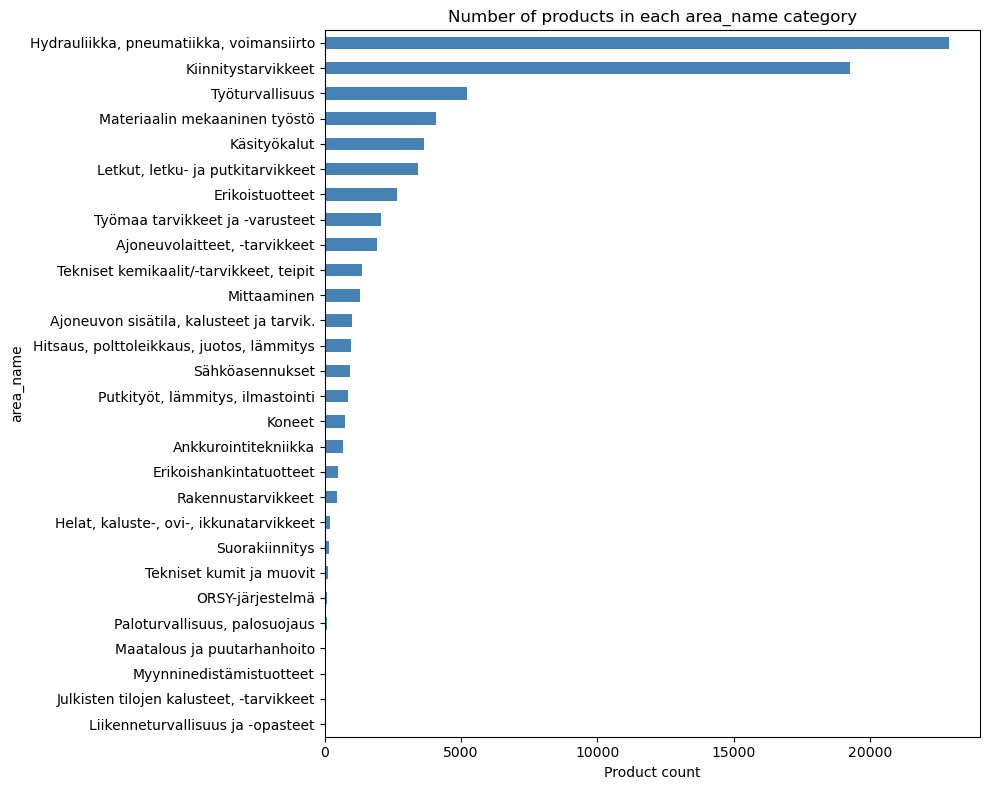

In [8]:
# clear horizontal bar chart for reporting
plt.figure(figsize=(10, 8))
area_counts.plot(kind='barh', color='steelblue')
plt.title('Number of products in each area_name category')
plt.xlabel('Product count')
plt.gca().invert_yaxis()  # set the largest category at the top
plt.tight_layout()
plt.show()

## 2 Lengths of headings and descriptions

In [ ]:
# word counts for key text fields 
product_data['title_word_count'] = product_data['product_label'].dropna().str.split().str.len()
product_data['title_word_count'] = product_data['product_label'].dropna().str.split().str.len()
product_data['short_desc_word_count'] = product_data['short_text_usp'].dropna().str.split().str.len()
product_data['desc_word_count'] = product_data['description'].dropna().str.split().str.len()

In [11]:
# summary statistics (count, mean, min, 25%, median, 75%, max)
length_summary = product_data[['title_word_count', 'short_desc_word_count', 'desc_word_count']].describe().round(1)
length_summary

,title_word_count,short_desc_word_count,desc_word_count
count,74465.0,50583.0,62828.0
mean,4.1,9.3,80.0
std,1.5,6.7,67.8
min,1.0,1.0,3.0
25%,3.0,5.0,36.0
50%,4.0,8.0,65.0
75%,5.0,12.0,100.0
max,10.0,101.0,991.0


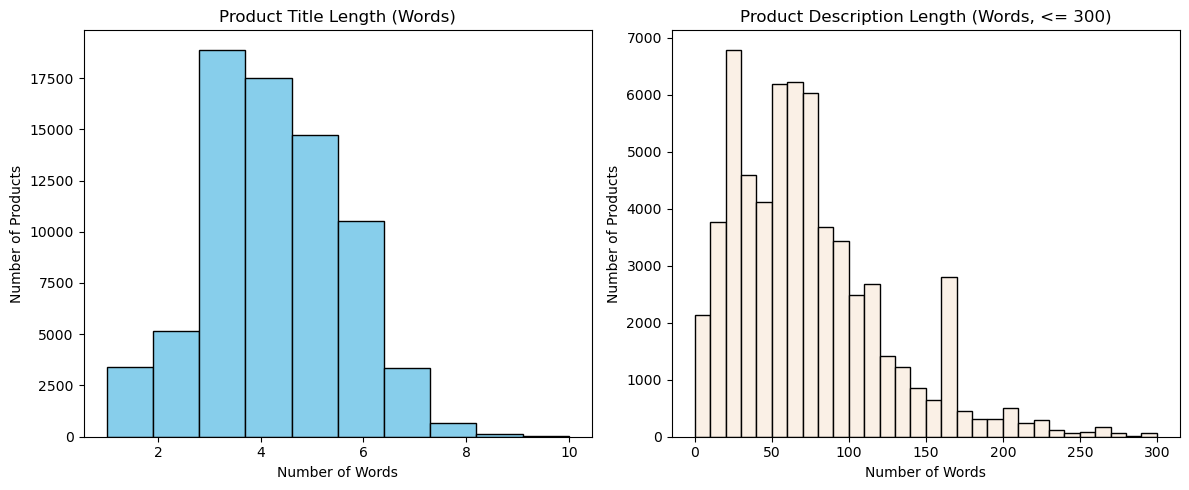

In [13]:
# side-by-side histograms for title and description lengths
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Title word count distribution
product_data['title_word_count'].plot(
    kind='hist', 
    bins=10, 
    color='skyblue', 
    edgecolor='black', 
    ax=axes[0]
)
axes[0].set_title('Product Title Length (Words)')
axes[0].set_xlabel('Number of Words')
axes[0].set_ylabel('Number of Products')
# Description word count distribution (capped at 300 words for readability)
product_data['desc_word_count'].plot(
    kind='hist', 
    bins=30, 
    range=(0, 300), 
    color='linen', 
    edgecolor='black', 
    ax=axes[1]
)
axes[1].set_title('Product Description Length (Words, <= 300)')
axes[1].set_xlabel('Number of Words')
axes[1].set_ylabel('Number of Products')
plt.tight_layout()
plt.show()

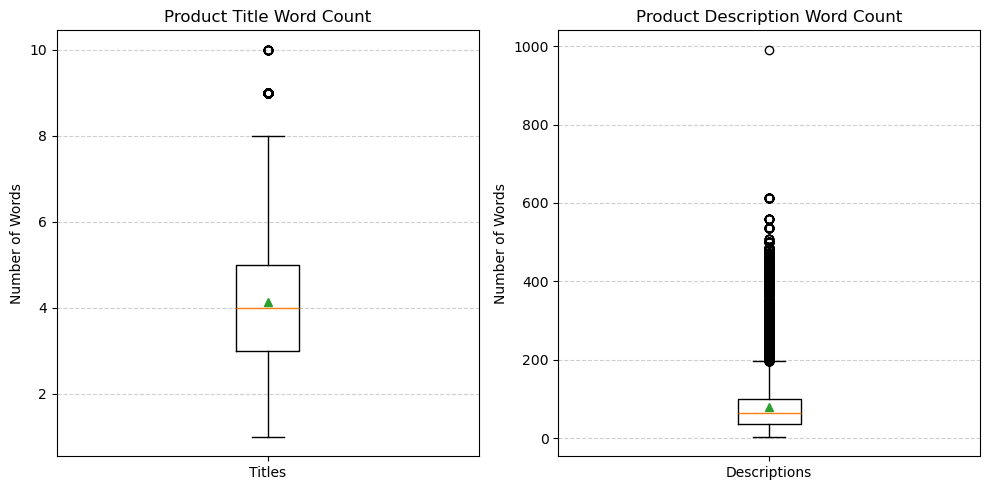

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))


# product title word count
axes[0].boxplot(
    product_data['title_word_count'].dropna(),
    showmeans=True, 
    tick_labels=['Titles']
)
axes[0].set_title('Product Title Word Count')
axes[0].set_ylabel('Number of Words')
axes[0].grid(axis='y', linestyle='--', alpha=0.6)



# product description word count
axes[1].boxplot(
    product_data['desc_word_count'].dropna(),
    showmeans=True,
    tick_labels=['Descriptions']
)
axes[1].set_title('Product Description Word Count')
axes[1].set_ylabel('Number of Words')
axes[1].grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Box: 25% - 75% interquartile range
Orange line: median
Green triangle: mean
Points outside of box: outliers

## 3 Vocabulary, Zipf's law

The most common word supposed to occur double times more related to 2.nd common word and so on. We'll looking that does the technical text behave in same way than natural language.

In [16]:
# collect and lowercase words
titles = product_data['product_label'].dropna()
words = [word for title in titles for word in title.lower().split()]

fdist = FreqDist(words)

print(f"Total tokens (N): {fdist.N():,}")
print(f"Unique vocabulary (B): {fdist.B():,}")

Total tokens (N): 307,843
Unique vocabulary (B): 47,332


In [18]:
print("Top 15 words:")
for word, count in fdist.most_common(15):
    print(f"{word}: {count}")

Top 15 words:
fag: 7052
zn: 5576
din: 4115
ina: 3552
iso: 3118
kuusioruuvi: 2504
lier.rll: 2440
turvaj: 2420
mm: 2393
8.8: 2118
sylinteri: 1616
kiilahihna: 1480
conti-v: 1409
jalas: 1397
pall.rll: 1217


<Axes: title={'center': 'Top 15 Most Common Words (NLTK FreqDist)'}, xlabel='Samples', ylabel='Counts'>

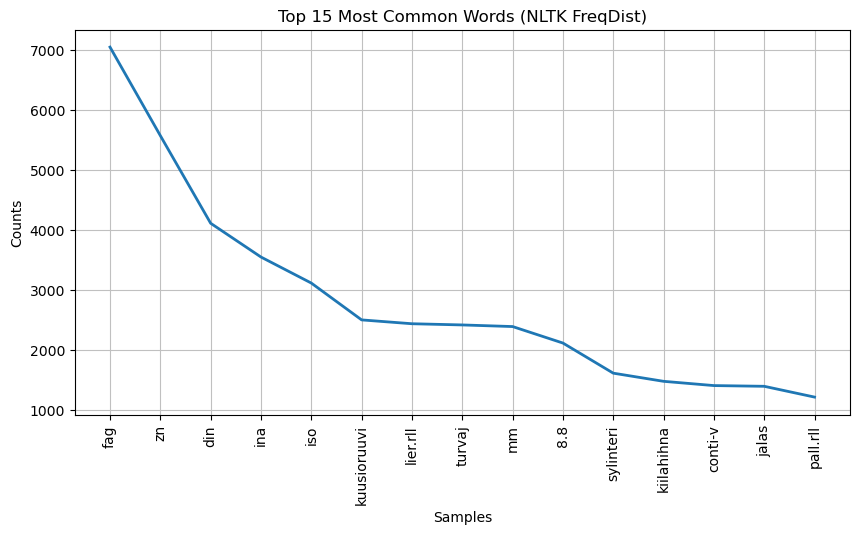

In [19]:
plt.figure(figsize=(10, 5))
fdist.plot(15, title='Top 15 Most Common Words (NLTK FreqDist)', cumulative=False)

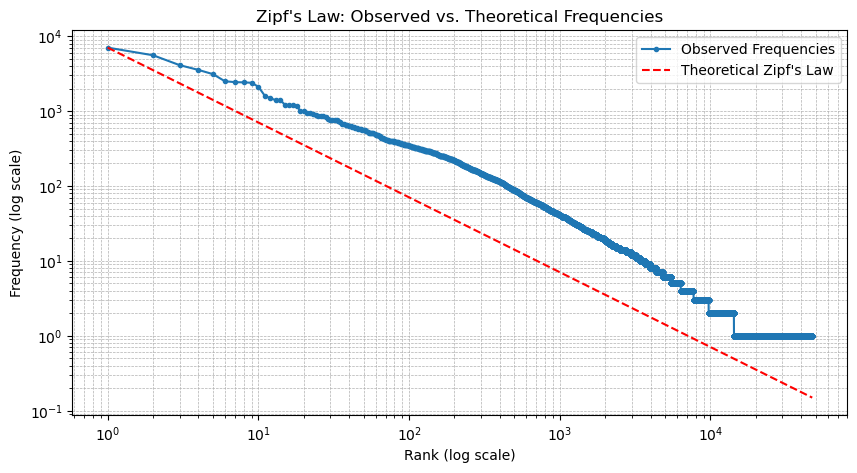

In [21]:
frequencies = [count for _, count in fdist.most_common()]
ranks = list(range(1, len(frequencies) + 1))
theoretical_zipf = [frequencies[0] / r for r in ranks]

plt.figure(figsize=(10, 5))
plt.loglog(ranks, frequencies, marker='.', label='Observed Frequencies')
plt.loglog(ranks, theoretical_zipf, linestyle='--', color='red', label='Theoretical Zipf\'s Law')
plt.title('Zipf\'s Law: Observed vs. Theoretical Frequencies')
plt.xlabel('Rank (log scale)')
plt.ylabel('Frequency (log scale)')
plt.legend()
plt.grid(True, which="both", ls="--", linewidth=0.5)

Observed line follows theoretical Zipf's Law line quite well. So it can be confirmed that catalog follows nlp power law.

## 4 Frequency of codes and units

In [32]:
import re

titles = product_data['product_label'].dropna()

# 1. Classify the anatomy of every product title (100% of data)
def classify_title(title):
    has_letters = bool(re.search(r'[a-zA-ZäöåÄÖÅ]', title))
    has_digits = bool(re.search(r'\d', title))
    
    if has_letters and has_digits:
        return 'Both words & codes/numbers'
    elif has_digits:
        return 'Codes/numbers only'
    elif has_letters:
        return 'Pure words only'
    return 'Other'

title_distribution = titles.apply(classify_title).value_counts(normalize=True) * 100

print("Product Title Composition (% of Catalog):")
print(title_distribution.round(1))


Product Title Composition (% of Catalog):
product_label
Both words & codes/numbers    96.6
Pure words only                3.4
Name: proportion, dtype: float64


In [30]:
# collect all tokens from product titles
titles = product_data['product_label'].dropna()
all_tokens = [token for title in titles for token in title.split()]

# classify every single token
def classify_token(token):
    has_letters = bool(re.search(r'[a-zA-ZäöåÄÖÅ]', token))
    has_digits = bool(re.search(r'\d', token))
    
    if has_letters and not has_digits and re.fullmatch(r'[a-zA-ZäöåÄÖÅ]+', token):
        return 'Pure Words (e.g. ruuvi, jalas)'
    elif has_letters and has_digits:
        return 'Alphanumeric Codes (e.g. M8x40, TX25)'
    elif has_digits and not has_letters and re.fullmatch(r'\d+', token):
        return 'Pure Numbers (e.g. 5, 24, 42)'
    else:
        return 'Dimensions & Symbols (e.g. 1/2", 8.8)'
    
# count frequencies and calculate percentages
token_counts = pd.Series([classify_token(t) for t in all_tokens]).value_counts()
token_pcts = (token_counts / len(all_tokens)) * 100

# print clean summary table
token_summary = pd.DataFrame({'Token Count': token_counts, 'Percentage (%)': token_pcts.round(1)})
print(token_summary)

                                       Token Count  Percentage (%)
Pure Words (e.g. ruuvi, jalas)              151729            49.3
Alphanumeric Codes (e.g. M8x40, TX25)        86579            28.1
Dimensions & Symbols (e.g. 1/2", 8.8)        42820            13.9
Pure Numbers (e.g. 5, 24, 42)                26715             8.7


Catalog vocabulary is clearly devided into words and technical codes, so search supposed to manage technical codes as well as natural language.